In [9]:
import math
import numpy as np
import matplotlib.pyplot as plt
from graphviz import Digraph
import random
%matplotlib inline

In [25]:
class Value:
    def __init__(self, x, parent=None, label='' ):
        if parent == None:
            parent = set()
        self._prev = parent
        self.label = label
        self.data = x
        self._op = ""
        self._backward = lambda : None
        self.grad = 0.0

        




        


    def backward(self):
        self.grad = 1.0
        topo = []
        visited = set()

        def sort(child):
            if child not in visited:
                visited.add(child)
                for k in child._prev:
                    sort(k)
                topo.append(child)


        sort(self)
        
        for child in reversed(topo):
            child._backward()

    def zero_grad(self):
        topo = []
        visited = set()

        def sort(child):
            if child not in visited:
                visited.add(child)
                for k in child._prev:
                    sort(k)
                topo.append(child)


        sort(self)
        
        for child in reversed(topo):
            child.grad = 0.0
    def __repr__(self):
        return f'Value({self.data})'


    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other))

        def _backward():
            self.grad += out.grad * 1
            other.grad += out.grad * 1

        out._backward = _backward
        out._op = '+'
        return out

    def log(self):
        out = Value(math.log(self.data), (self,))

        def _backward():
            self.grad += out.grad / self.data

        out._backward = _backward
                
        out._op = 'log'
        return out

    def __radd__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other))

        def _backward():
            self.grad += out.grad * 1
            other.grad += out.grad * 1

        out._backward = _backward
                
        out._op = '+'
        return out

    def __neg__(self):
        return (-1)*self


    def relu(self):
        out = Value(self.data if self.data > 0 else 0, (self,))
        out._op = 'relu'

        def _backward():
            self.grad += out.grad * (out.data > 0)

        out._backward = _backward

        return out

    def __sub__(self, other):
        return self + (-other)

    def __rsub__(self, other):
            return (-self) + other

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other))
        def _backward():
            self.grad += out.grad * other.data
            other.grad += out.grad * self.data

        out._backward = _backward
        out._op = '*'
        return out

    






    
    def __truediv__(self, other):
        return self*(other**-1)


    def __rtruediv__(self, other):
        return other*(self**-1)

    def tanh(self):
        out = Value((math.exp(2*self.data) - 1)/(math.exp(2*self.data) + 1), (self,))
        out._op = 'tanh'

        def _backward():
            self.grad += out.grad * (1-(out.data**2)) 

        out._backward = _backward

        return out
    
    def exp(self):
        out = Value(math.exp(self.data), (self,))
        out._op = 'exp'

        def _backward():
            self.grad += out.grad * out.data

        out._backward = _backward

        return out


    def __rmul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other))
        def _backward():
            self.grad += out.grad * other.data
            other.grad += out.grad * self.data

        out._backward = _backward
        out._op = '*'
        return out



    def __pow__(self, other):
        assert isinstance(other, (int, float)), "we are currently using float or int to calculate pow"
        out = Value(self.data**other, (self,))
        
        def _backward():
            self.grad += out.grad * other * self.data**(other-1)

        out._backward = _backward
        out._op = f'**{other}'
        return out



def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root, format='svg', rankdir='LR'):
    """
    format: png | svg | ...
    rankdir: TB (top to bottom graph) | LR (left to right)
    """
    assert rankdir in ['LR', 'TB']
    nodes, edges = trace(root)
    dot = Digraph(format=format, graph_attr={'rankdir': rankdir}) #, node_attr={'rankdir': 'TB'})
    
    for n in nodes:
        dot.node(name=str(id(n)), label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            dot.node(name=str(id(n)) + n._op, label=n._op)
            dot.edge(str(id(n)) + n._op, str(id(n)))
    
    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    
    return dot


def grad_check(params, loss_fn, h):
        loss = loss_fn()
        loss.zero_grad()
        loss.backward()
        original = [cell.grad for cell in params]
        print(original)
        after = []
        for i in range(len(params)):
            param = params[i]
            param.data += h
            ph = loss_fn().data
            param.data -= 2*h
            mh = loss_fn().data
            param.data += h
            after.append((ph-mh)/(2*h))
        print(after)
        
        return max([abs(a - b) / max(abs(a), abs(b), 1e-8) for (a,b) in zip(original, after)])

In [19]:
class Neuron:
    def __init__(self, nin):
        self.nin = nin
        self.w = []
        self.b = Value(random.uniform(-1,1))
        for i in range(nin):
            self.w.append(Value(random.uniform(-1, 1)))

    def __call__(self, x, activation=True):
        if (activation):
            return sum((wi * xi for (wi, xi) in zip(self.w, x)), self.b).tanh()
        else:
            return sum((wi * xi for (wi, xi) in zip(self.w, x)), self.b)
        

    def parameters(self):
        return self.w + [self.b]




class Layer:
    def __init__(self, nin, nout):
        self.nin = nin
        self.nout = nout
        self.neurons = []
        for i in range(self.nout):
            self.neurons.append(Neuron(self.nin))

    def __call__(self, x, activation=True, last=False):
        if (last):
            if (activation):
                return self.neurons[0](x)
            else:
                return self.neurons[0](x, False)

        else:
            if(activation):
                return [neuron(x) for neuron in self.neurons]
            else:
                return [neuron(x, False) for neuron in self.neurons] 


    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]


class MLP:
    def __init__(self, nin, nouts):
        self.layers = []
        temp = [nin] + nouts
        for i in range(len(temp) - 1):
            self.layers.append(Layer(temp[i], temp[i+1]))


    def __call__(self, x):
        for i in range(len(self.layers) - 1):
            x = self.layers[i](x)
        x = self.layers[len(self.layers)-1](x, False, True)
        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]


        

In [4]:
a = Value(5.0)
b = Value(3.0)

def loss_fn():
    loss = a * b
    return loss
grad_check([a,b], loss_fn, 1e-5)

2.1354029655184268e-11

In [5]:
a = Value(5.0)
b = Value(3.0)

def loss_fn():
    loss = a / b
    return loss
grad_check([a,b], loss_fn, 1e-5)

2.653517405733584e-11

In [7]:
a = Value(5.0)
b = Value(3.0)

def loss_fn():
    loss = a ** 3
    return loss
grad_check([a], loss_fn, 1e-5)

4.774847184285074e-12

In [ ]:
a = Value(5.0)
b = Value(3.0)

def loss_fn():
    loss = a.log()
    return loss
grad_check([a], loss_fn, 1e-5)

2.8755470226355065e-11

In [11]:
a = Value(5.0)
b = Value(3.0)

def loss_fn():
    loss = a.exp()
    return loss
grad_check([a], loss_fn, 1e-5)

2.985949078075223e-11

In [17]:
a = Value(5.0)
b = Value(3.0)

def loss_fn():
    loss = a.tanh()
    return loss
grad_check([a], loss_fn, 1e-5)

0.49999999768610853

In [13]:
a = Value(5.0)
b = Value(3.0)

def loss_fn():
    loss = a.relu()
    return loss
grad_check([a], loss_fn, 1e-5)

6.551204023665206e-12

In [20]:
model = MLP(3, [4, 4, 1])
x = [2.0, 3.0, -1.0]
print(model(x))    
print(len(model.parameters()))

Value(0.3683865751736355)
41


In [56]:
import torch

x1 = torch.tensor(2.0, dtype=torch.float64, requires_grad=True)
x2 = torch.tensor(0.0, dtype=torch.float64, requires_grad=True)
w1 = torch.tensor(-3.0, dtype=torch.float64, requires_grad=True)
w2 = torch.tensor(1.0, dtype=torch.float64, requires_grad=True)
b  = torch.tensor(6.8813735870195432, dtype=torch.float64, requires_grad=True)

n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

o.backward()

print(o.item())
print(x1.grad.item(), w1.grad.item(), x2.grad.item(), w2.grad.item())







0.7071067811865476
-1.4999999999999996 0.9999999999999998 0.4999999999999999 0.0


In [26]:
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0]

model = MLP(3, [4, 4, 1])

for i in range(200):
    ypred = [model(xi) for xi in xs]
    loss = sum((yp-yi)**2 for (yp, yi) in zip(ypred, ys))
    print(i, loss.data)
    loss.backward()
    for node in model.parameters():
        node.data += -0.05 * node.grad
    loss.zero_grad()



print([model(xi).data for xi in xs])

def loss_fn():
    ypred = [model(xi) for xi in xs]
    loss = sum((yp-yi)**2 for (yp, yi) in zip(ypred, ys))
    return loss

grad_check(model.parameters(), loss_fn, 1e-5)

0 5.13873767848001
1 3.3467462113112125
2 2.9564117760858877
3 3.030073941235843
4 3.0413266899034594
5 3.1517669672093005
6 2.580406128913867
7 1.727316533226607
8 0.9723623337845189
9 0.493804736740067
10 0.3028780514863409
11 0.21108103689440894
12 0.15824525588462535
13 0.12254113696322916
14 0.09659965592862647
15 0.07703370811241049
16 0.061947171345970664
17 0.050131960429352786
18 0.04077128392230383
19 0.033291051748266604
20 0.027275825471219758
21 0.022416703321596083
22 0.018478693467134637
23 0.015279578616945738
24 0.012675995018753225
25 0.010553926699258956
26 0.008822012352530984
27 0.007406666419949129
28 0.00624842013545226
29 0.005299109737575238
30 0.004519676095141104
31 0.0038784194857323082
32 0.003349602522702181
33 0.002912324791756127
34 0.0025496127355038784
35 0.002247681808093634
36 0.001995337451508327
37 0.001783488425685304
38 0.0016047513107676215
39 0.0014531291019056459
40 0.0013237500595879711
41 0.0012126555737436368
42 0.001116627894346311
43 0.00

2.9768243754862702e-06

_IncompleteInputError: incomplete input (2920863220.py, line 1)

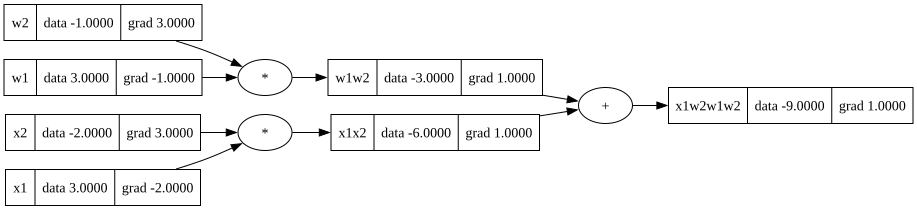

In [37]:
x1 = Value(3.0); x1.label = 'x1'
x2 = Value(-2.0); x2.label = 'x2'
x1x2 = x1 * x2; x1x2.label = 'x1x2'
w1 = Value(3.0); w1.label = 'w1'
w2 = Value(-1.0); w2.label = 'w2'
w1w2 = w1 * w2; w1w2.label = 'w1w2'

x1x2w1w2 = x1x2 + w1w2; x1x2w1w2.label = 'x1w2w1w2'
x1x2w1w2.backward()


draw_dot(x1x2w1w2)

In [27]:
a = Value(3.0)


3 - a

Value(0.0)

In [38]:
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

b = Value(6.8813735870195432, label='b')

x1w1 = x1 * w1; x1w1.label = 'x1w1'
x2w2 = x2 * w2; x2w2.label = 'x2w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1w1 + x2w2'
n = x1w1x2w2 + b; n.label = 'n'

o = n.tanh(); o.label = 'o'
o.grad = 1.0
o.backward()

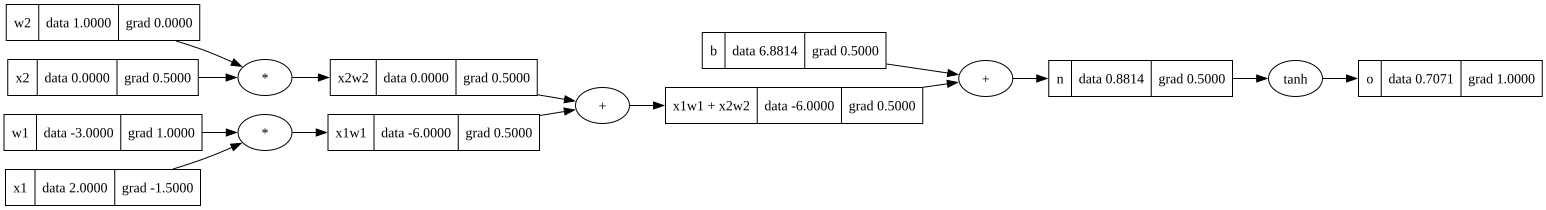

In [39]:
draw_dot(o)

0 10.879330634082555
1 6.008926594972664
2 3.635647424252067
3 2.3208877864300628
4 1.553964126446166
5 1.0945709725702366
6 0.8158687880221197
7 0.6453472183531099
8 0.5405105551421869
9 0.47585249213385844
10 0.4358756352362409
11 0.4111058329530178
12 0.3957236455713137
13 0.38613134163344337
14 0.38011188271001667
15 0.3762977710036547
16 0.37384827395009773
17 0.37224275231515275
18 0.37115673219097717
19 0.37039127390410637
20 0.3698235199341485
21 0.3693795921488755
22 0.3690199654521669
23 0.36870749757008214
24 0.36842391159663107
25 0.3681579129238219
26 0.36790252089288594
27 0.36765972634192196
28 0.36742565471951305
29 0.36719356402015096
30 0.36696242116648525
31 0.36673158702807096
32 0.3665006651220519
33 0.3662694085934841
34 0.36603766290187184
35 0.36580533046857144
36 0.3655723488587283
37 0.365338677313394
38 0.3651042884359685
39 0.3648691630609512
40 0.36463328708755244
41 0.3643966495263971
42 0.36415924129507643
43 0.3639210544758702
44 0.3636820818586309
45 0.

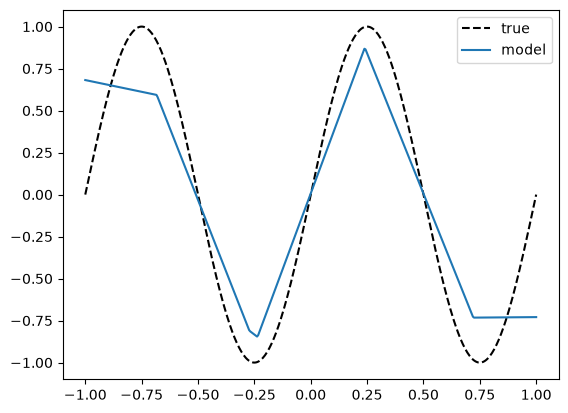

In [39]:
xs = [-1 + 0.04 * i for i in range(50)]
ys = [math.sin((-1 + 0.04 * i) * 2 * math.pi) for i in range(50)]

model = MLP(1, [8, 1])
for n in model.layers[0].neurons:
    w = random.choice([-1, 1]) * random.uniform(1, 3)   # 기울기: 크기 1~3, 부호 무작위
    c = random.uniform(-1, 1)                            # 꺾이는 점 위치
    n.w[0].data = w
    n.b.data = -w * c                                    
for i in range(2000):
    ypred = [model([xi]) for xi in xs]
    loss = sum((yp-yi)**2 for (yp, yi) in zip(ypred, ys)) / 50
    print(i, loss.data)
    loss.backward()
    for node in model.parameters():
        node.data += -0.02 * node.grad
    loss.zero_grad()



xs = np.linspace(-1, 1, 400)

plt.plot(xs, np.sin(2*np.pi*xs), label='true', color='black', linestyle='--')
plt.plot(xs, [model([x]).data for x in xs], label='model', color='tab:blue')

plt.legend()
plt.show()